In [1]:
import torch
# Check for Gpu

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


In [2]:
import pandas as pd
df = pd.read_csv('/content/fmnist_small.csv')

In [3]:
df.head()

,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,9,0,0,0,0,0,0,0,0,0,...,0,7,0,50,205,196,213,165,0,0
1,7,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,1,0,0,0,...,142,142,142,21,0,3,0,0,0,0
3,8,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,8,0,0,0,0,0,0,0,0,0,...,213,203,174,151,188,10,0,0,0,0


In [4]:
import numpy as np
import sklearn.model_selection as model_selection
import torch
from torch.utils.data import Dataset, DataLoader
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

In [5]:
# set random seeds for productivity
torch.manual_seed(42)


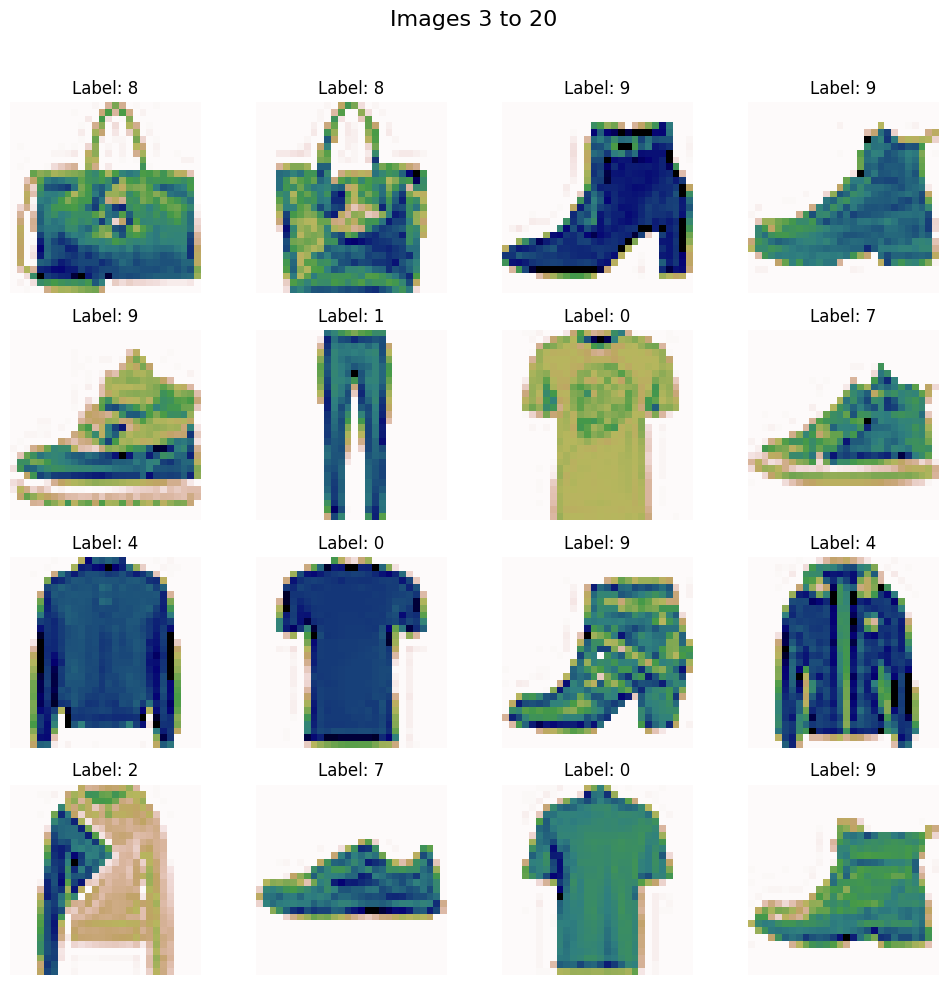

In [6]:
start = 3
end = 20              # last image to show (included)
n = end - start + 1   # 17 images

fig, axes = plt.subplots(4, 4, figsize=(10, 10))
fig.suptitle(f'Images {start} to {end}', fontsize=16)

for k, ax in enumerate(axes.flat):
  if k < n:
    i = start + k
    img = df.iloc[i, 1:].values.reshape(28, 28)
    ax.imshow(img, cmap='gist_earth_r')
    ax.set_title(f"Label: {df.iloc[i, 0]}")
  ax.axis('off')

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

In [7]:
# train test split

x = df.iloc[:, 1:].values
y = df.iloc[:, 0].values



In [8]:
x_train, x_test, y_train, y_test = model_selection.train_test_split(x, y, test_size=0.2, random_state=42)

In [9]:
print(x_train.shape)
print(y_train.shape)


(4800, 784)
(4800,)


In [10]:
x_train = x_train/255.0
x_test = x_test/255.0

In [11]:
x_train

array([[0.       , 0.       , 0.       , ..., 0.       , 0.       ,
        0.       ],
       [0.       , 0.       , 0.       , ..., 0.       , 0.       ,
        0.       ],
       [0.       , 0.       , 0.       , ..., 0.       , 0.       ,
        0.       ],
       ...,
       [0.       , 0.       , 0.       , ..., 0.       , 0.       ,
        0.       ],
       [0.       , 0.       , 0.       , ..., 0.       , 0.       ,
        0.       ],
       [0.       , 0.       , 0.       , ..., 0.0627451, 0.       ,
        0.       ]], shape=(4800, 784))

In [12]:
# Create custom dataset class
class CustomDataset(Dataset):
  def __init__(self, features, labels):
    self.features = torch.tensor(features, dtype=torch.float32)
    self.labels = torch.tensor(labels, dtype=torch.long)

  def __len__(self):
    return len(self.features)

  def __getitem__(self, idx):
    return self.features[idx], self.labels[idx]

In [13]:
# create train dataset object
train_dataset = CustomDataset(x_train, y_train)


In [14]:
train_dataset[0][1]

tensor(7)

In [15]:
# create test obj
test_dataset = CustomDataset(x_test, y_test)

In [16]:
# create train and test loader
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, pin_memory=True)

In [30]:
# model
class MyNN(nn.Module):
  def __init__(self, input_dim, output_dim, num_hidden_layers, neurons_per_layer):
    super().__init__()

    layers = []

    for i in range(num_hidden_layers):
      layers.append(nn.Linear(input_dim, neurons_per_layer))
      layers.append(nn.BatchNorm1d(neurons_per_layer))
      layers.append(nn.ReLU())
      layers.append(nn.Dropout(p=0.3))
      input_dim = neurons_per_layer

    layers.append(nn.Linear(input_dim, output_dim))

    self.model = nn.Sequential(*layers)

  def forward(self, x):
    return self.model(x)

# Objective function

In [31]:
 # objective function
def objective(trial):
  # next hyperparameter values frem the search space
  num_hidden_layers = trial.suggest_int("num_hidden_layers", 1, 5)
  neurons_per_layer = trial.suggest_int("neurons_per_layer", 8, 128, step=8)


  # model init
  input_dim = 784
  output_dim = 10

  model = MyNN(input_dim, output_dim, num_hidden_layers, neurons_per_layer)
  model = model.to(device)

  # paraam init
  epochs = 100
  learning_rate = 0.1



  # optimizer selection
  criterion = nn.CrossEntropyLoss()
  optimizer = optim.SGD(model.parameters(), lr=learning_rate, weight_decay=1e-4)



  # training loop
  total_loss = 0.0
  for epoch in range(epochs):
    total_epoch_loss = 0.0
    loss = 0.0
    for batch_features, batch_labels in train_loader:

      # move to gpu
      batch_features = batch_features.to(device)
      batch_labels = batch_labels.to(device)

      # forward pass
      outputs = model(batch_features)

      #calculate loss
      loss = criterion(outputs, batch_labels)

      optimizer.zero_grad()
      # backprop
      loss.backward()

      #update weights
      optimizer.step()


    # evalution
    model.eval()

    # evalution code
    total = 0.0
    correct = 0.0
    with torch.no_grad():
      for batch_features, batch_labels in test_loader:

        #move to gpu
        batch_features = batch_features.to(device)
        batch_labels = batch_labels.to(device)

        outputs = model(batch_features)

        predictions = torch.argmax(outputs, dim=1)
        total += batch_labels.size(0)
        correct += (predictions == batch_labels).sum().item()

    accuracy = correct/total

  return accuracy


In [32]:
!pip install optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [optuna]


In [33]:
import optuna
study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=10)

[I 2026-11-07 20:19:16,783] A new study created in memory with name: no-name-0e77cc7c-e5e4-4918-9c2a-a115ec35f7a5
[I 2026-11-07 20:20:06,824] Trial 0 finished with value: 0.8525 and parameters: {'num_hidden_layers': 5, 'neurons_per_layer': 24}. Best is trial 0 with value: 0.8525.
[I 2026-11-07 20:20:33,798] Trial 1 finished with value: 0.84 and parameters: {'num_hidden_layers': 1, 'neurons_per_layer': 88}. Best is trial 0 with value: 0.8525.
[I 2026-11-07 20:21:01,208] Trial 2 finished with value: 0.8325 and parameters: {'num_hidden_layers': 1, 'neurons_per_layer': 112}. Best is trial 0 with value: 0.8525.
[I 2026-11-07 20:21:51,888] Trial 3 finished with value: 0.8516666666666667 and parameters: {'num_hidden_layers': 5, 'neurons_per_layer': 128}. Best is trial 0 with value: 0.8525.
[I 2026-11-07 20:22:37,099] Trial 4 finished with value: 0.8458333333333333 and parameters: {'num_hidden_layers': 4, 'neurons_per_layer': 104}. Best is trial 0 with value: 0.8525.
[I 2026-11-07 20:23:26,916

In [34]:
study.best_value

0.8525

In [35]:
study.best_params

{'num_hidden_layers': 5, 'neurons_per_layer': 24}

In [29]:
# in training data
total = 0.0
correct = 0.0
with torch.no_grad():
  for batch_features, batch_labels in train_loader:

    #move to gpu
    batch_features = batch_features.to(device)
    batch_labels = batch_labels.to(device)

    outputs = model(batch_features)

    predictions = torch.argmax(outputs, dim=1)
    total += batch_labels.size(0)
    correct += (predictions == batch_labels).sum().item()

accuracy = correct/total
print(f"Accuracy: {accuracy}")

Accuracy: 0.9910416666666667
